In [3]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy
import seaborn as sns
import statsmodels.api as sm
from collections import defaultdict
import re

In [ ]:
df = pd.read_csv("data/raw/train.csv")

pattern = re.compile(r'(?P<area>[^_]+)_(?P<depth>L\d+)_(?P<ctype>[^_]+)_time_')

combinations = set()

for col in df.columns:
    m = pattern.match(col)
    if m:
        combinations.add((m.group("area"), m.group("depth"), m.group("ctype")))

print("Combinaisons Area / Depth / Type trouvées :")
for x in sorted(combinations):
    print(x)


Combinaisons Area / Depth / Type trouvées :
('A1', 'L1', 'EXC')
('A1', 'L1', 'INH')
('A1', 'L4', 'EXC')
('A1', 'L4', 'INH')
('A1', 'L5', 'EXC')
('A1', 'L5', 'INH')
('ALM', 'L1', 'EXC')
('ALM', 'L1', 'INH')
('ALM', 'L5', 'EXC')
('ALM', 'L5', 'INH')
('wM2', 'L1', 'EXC')
('wM2', 'L1', 'INH')
('wM2', 'L5', 'EXC')
('wM2', 'L5', 'INH')
('wS1', 'L1', 'EXC')
('wS1', 'L1', 'INH')
('wS1', 'L4', 'EXC')
('wS1', 'L4', 'INH')
('wS1', 'L5', 'EXC')
('wS1', 'L5', 'INH')
('wS2', 'L1', 'EXC')
('wS2', 'L1', 'INH')
('wS2', 'L4', 'EXC')
('wS2', 'L4', 'INH')
('wS2', 'L5', 'EXC')
('wS2', 'L5', 'INH')


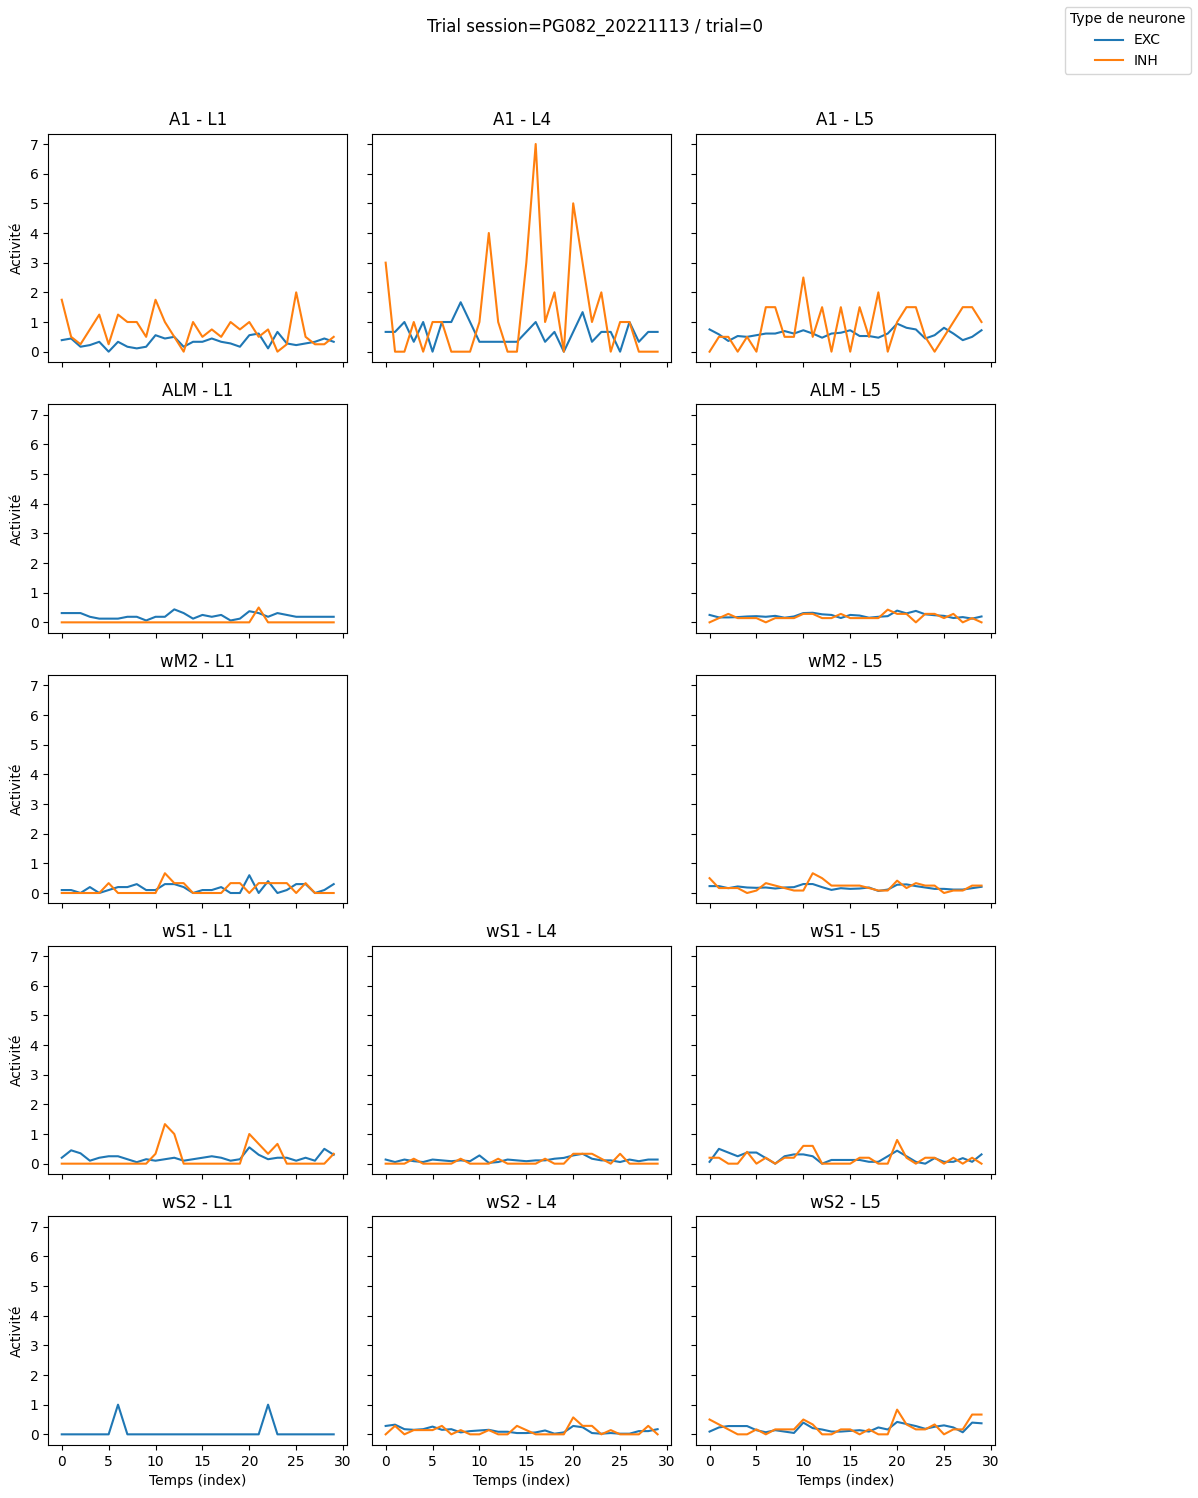

In [9]:

df = pd.read_csv("data/raw/train.csv")

# 1. Charger le train set
df = pd.read_csv("data/raw/train.csv")

# 1bis. Imputer les NaN par la moyenne conditionnelle au TRIAL_TYPE
# On détecte la colonne de cible contenant "trial_type" (insensible à la casse)
target_candidates = [c for c in df.columns if c.lower() == "trial_type"] or [
    c for c in df.columns if "trial_type" in c.lower()
]
if not target_candidates:
    raise ValueError("Colonne TRIAL_TYPE introuvable pour l'imputation conditionnelle.")
target_col = target_candidates[0]

# Colonnes neurones uniquement (on exclut les métadonnées)
pattern = re.compile(r'(?P<region>[^_]+)_(?P<layer>L\d+)_(?P<ctype>[^_]+)_time_(?P<t>\d+)')
neural_cols = [col for col in df.columns if pattern.match(col)]

# Moyennes par type de trial puis remplissage
group_means = df.groupby(target_col)[neural_cols].transform("mean")
df[neural_cols] = df[neural_cols].fillna(group_means)

# 2. On prend un trial (ici la première ligne)
row = df.iloc[0]

# 3. Transformer les colonnes neurones en format "long"
#    Colonnes du type : REGION_LAYER_TYPE_time_T
records = []
for col, val in row.items():
    m = pattern.match(col)
    if m:
        d = m.groupdict()
        d["time"] = int(d.pop("t"))
        d["value"] = float(val)
        records.append(d)

long_df = pd.DataFrame(records)

# 4. Récupérer les régions / couches / types présents
regions = sorted(long_df["region"].unique())
layers  = sorted(long_df["layer"].unique())
ctypes  = sorted(long_df["ctype"].unique())

# 5. Créer la grille de subplots : lignes = régions, colonnes = couches
n_rows = len(regions)
n_cols = len(layers)

fig, axes = plt.subplots(n_rows, n_cols,
                         figsize=(4 * n_cols, 3 * n_rows),
                         sharex=True, sharey=True)

# Normaliser axes pour gérer les cas 1x1, 1xn, nx1
if n_rows == 1 and n_cols == 1:
    axes = np.array([[axes]])
elif n_rows == 1:
    axes = axes[np.newaxis, :]
elif n_cols == 1:
    axes = axes[:, np.newaxis]

# 6. Boucle sur (région, couche) et tracé d'une courbe par type de neurone
for i, region in enumerate(regions):
    for j, layer in enumerate(layers):
        ax = axes[i, j]

        sub = long_df[(long_df["region"] == region) &
                      (long_df["layer"]  == layer)]

        if sub.empty:
            ax.set_axis_off()
            continue

        for c in ctypes:
            sub_c = sub[sub["ctype"] == c].sort_values("time")
            if sub_c.empty:
                continue
            ax.plot(sub_c["time"], sub_c["value"], label=c)

        ax.set_title(f"{region} - {layer}")
        if i == n_rows - 1:
            ax.set_xlabel("Temps (index)")
        if j == 0:
            ax.set_ylabel("Activité")

# 7. Légende (prise sur le premier subplot non vide)
handles, labels = axes[0, 0].get_legend_handles_labels()
if handles:
    fig.legend(handles, labels, loc="upper right", title="Type de neurone")

fig.suptitle(f"Trial session={row['session_id']} / trial={row['trial_number']}",
             y=0.99)
fig.tight_layout(rect=[0, 0, 0.85, 0.96])

plt.show()


In [ ]:
# Modèle de classification simple avec sklearn- imputation par groupe

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score
from sklearn.impute import SimpleImputer # Pour gérer les valeurs manquantes

# Charger le dataset
df = pd.read_csv("data/raw/train.csv")


# ---- IMPUTATION PAR GROUPE (TRIAL_TYPE) ----
features = df.drop(columns=["session_id", "trial_number", "TRIAL_TYPE"])
features_imputed = features.groupby(df["TRIAL_TYPE"]).transform(lambda x: x.fillna(x.mean()))

# On reconstruit un dataframe propre avec les features imputées
df_imputed = df.copy()
df_imputed[features.columns] = features_imputed
# --------------------------------------------


# Features et labels
X = df_imputed.drop(columns=["session_id", "trial_number", "TRIAL_TYPE"])
y = df_imputed["TRIAL_TYPE"]

# Split train/test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=0
)
imputer = SimpleImputer(strategy="mean") #replace missing values with mean of the column


X_train = imputer.fit_transform(X_train)
X_test  = imputer.transform(X_test)

I = np.linspace(0.0001,1, 10)

best_acc = 0
best_C = None
best_l = 0
for i in I:
    for l in ["l1", "l2"] :
        model = LogisticRegression(
            penalty= l,
            max_iter= 1000,
            C=i)       
        
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    if acc > best_acc :
        best_acc = acc
        best_C = i
        best_l = l
print(best_acc, best_l, best_C)
    
# probleme here is that we fill the datamatrix with the mean of all the data and do not take 
# care to avoid using test set 
    

/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/sklearn/impute/_base.py:653: UserWarning: Skipping features without any observed values: ['wS2_L1_INH_time_0' 'wS2_L1_INH_time_1' 'wS2_L1_INH_time_2'
 'wS2_L1_INH_time_3' 'wS2_L1_INH_time_4' 'wS2_L1_INH_time_5'
 'wS2_L1_INH_time_6' 'wS2_L1_INH_time_7' 'wS2_L1_INH_time_8'
 'wS2_L1_INH_time_9' 'wS2_L1_INH_time_10' 'wS2_L1_INH_time_11'
 'wS2_L1_INH_time_12' 'wS2_L1_INH_time_13' 'wS2_L1_INH_time_14'
 'wS2_L1_INH_time_15' 'wS2_L1_INH_time_16' 'wS2_L1_INH_time_17'
 'wS2_L1_INH_time_18' 'wS2_L1_INH_time_19' 'wS2_L1_INH_time_20'
 'wS2_L1_INH_time_21' 'wS2_L1_INH_time_22' 'wS2_L1_INH_time_23'
 'wS2_L1_INH_time_24' 'wS2_L1_INH_time_25' 'wS2_L1_INH_time_26'
 'wS2_L1_INH_time_27' 'wS2_L1_INH_time_28' 'wS2_L1_INH_time_29']. At least one non-missing value is needed for imputation with strategy='mean'.
  warnings.warn(
/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/sklearn/impute/_base.py:653: UserWarning

0.9009826152683296 l2 0.5556


In [7]:
#KNNI imputer and finding best parameters

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score

from sklearn.impute import KNNImputer

# Charger le dataset
df = pd.read_csv("data/raw/train.csv")
df = df.loc[:, df.nunique() > 1] # Remove constant columns

# Features et labels
X = df.drop(columns=["session_id", "trial_number", "TRIAL_TYPE"])
y = df["TRIAL_TYPE"]

# Split train/test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=0
)

# ======== IMPUTATION AVEC KNNImputer ========
imputer = KNNImputer(n_neighbors=5)
X_train = imputer.fit_transform(X_train)
X_test  = imputer.transform(X_test)
# ===============================================================

# Grid simple pour C et pénalité
I = np.linspace(0.0001, 1, 10)

best_acc = 0
best_C = None
best_l = None

for i in I:
    for l in ["l1", "l2"]:
        model = LogisticRegression(
            penalty=l,
            C=i,
            max_iter=1000,
            solver="liblinear"  # supporte L1 et L2
        )

        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        acc = accuracy_score(y_test, y_pred)

        if acc > best_acc:
            best_acc = acc
            best_C = i
            best_l = l

print("Best accuracy:", best_acc)
print("Best penalty:", best_l)
print("Best C:", best_C)

# ----- Re-train best model -----
best_model = LogisticRegression(
    penalty=best_l,
    C=best_C,
    max_iter=1000,
    solver="liblinear"
)
best_model.fit(X_train, y_train)
y_pred = best_model.predict(X_test)

print("Confusion matrix:\n", confusion_matrix(y_test, y_pred))
print("Accuracy:", accuracy_score(y_test, y_pred))

/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1296: FutureWarning: Using the 'liblinear' solver for multiclass classification is deprecated. An error will be raised in 1.8. Either use another solver which supports the multinomial loss or wrap the estimator in a OneVsRestClassifier to keep applying a one-versus-rest scheme.
  warnings.warn(
/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1296: FutureWarning: Using the 'liblinear' solver for multiclass classification is deprecated. An error will be raised in 1.8. Either use another solver which supports the multinomial loss or wrap the estimator in a OneVsRestClassifier to keep applying a one-versus-rest scheme.
  warnings.warn(
/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1296: FutureWarning: Using the 'liblinear' solver for multiclass classification is depreca

Best accuracy: 0.6787603930461074
Best penalty: l1
Best C: 0.11120000000000001


/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1296: FutureWarning: Using the 'liblinear' solver for multiclass classification is deprecated. An error will be raised in 1.8. Either use another solver which supports the multinomial loss or wrap the estimator in a OneVsRestClassifier to keep applying a one-versus-rest scheme.
  warnings.warn(


Confusion matrix:
 [[213   0   0   5   0   8   0   0   1   6]
 [  7   0   0   1   0  35   0   0   0  11]
 [  5   0   0  18   0   0   0   2   0   0]
 [  2   0   0 156   0   4   0  61   0  10]
 [ 18   0   0   0   0   2   0   0   1   1]
 [ 11   0   0   8   0 154   0  14   1  57]
 [  1   0   0   0   0   0   0   0   0   0]
 [  2   0   0  41   0   8   0 197   0  10]
 [ 13   0   0   0   0   0   0   0   7  15]
 [  2   0   0   3   0  37   0   4   0 171]]
Accuracy: 0.6787603930461074


In [9]:
#adaptation to use K folding cross validation
import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score
from sklearn.impute import KNNImputer

# Charger le dataset
df = pd.read_csv("data/raw/train.csv")
df = df.loc[:, df.nunique() > 1]  # Remove constant columns

# Features et labels
X = df.drop(columns=["session_id", "trial_number", "TRIAL_TYPE"])
y = df["TRIAL_TYPE"]

# ===================== 1) CRÉER LES 5 FOLDS =====================
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

folds = []  # ici on stocke explicitement les 5 X_train/X_test/y_train/y_test
for train_idx, test_idx in skf.split(X, y):
    X_train_cv = X.iloc[train_idx]
    X_test_cv  = X.iloc[test_idx]
    y_train_cv = y.iloc[train_idx]
    y_test_cv  = y.iloc[test_idx]
    folds.append((X_train_cv, X_test_cv, y_train_cv, y_test_cv))
# ===============================================================

# Grid simple pour C et pénalité
I = np.linspace(0.0001, 1, 10)

best_acc = 0
best_C = None
best_l = None

# ===================== 2) BOUCLE SUR LES 5 FOLDS =====================
for C in I:
    for l in ["l1", "l2"]:
        accs = []  # accuracies sur les 5 folds

        for X_train_cv, X_test_cv, y_train_cv, y_test_cv in folds:
            # Imputation à l'intérieur de chaque fold (pas de fuite d'info)
            imputer = KNNImputer(n_neighbors=5)
            X_train_imp = imputer.fit_transform(X_train_cv)
            X_test_imp  = imputer.transform(X_test_cv)

            model = LogisticRegression(
                penalty=l,
                C=C,
                max_iter=1000,
                solver="liblinear"  # supporte L1 et L2
            )

            model.fit(X_train_imp, y_train_cv)
            y_pred = model.predict(X_test_imp)
            acc = accuracy_score(y_test_cv, y_pred)
            accs.append(acc)

        mean_acc = np.mean(accs)

        if mean_acc > best_acc:
            best_acc = mean_acc
            best_C = C
            best_l = l

print("Best mean CV accuracy:", best_acc)
print("Best penalty:", best_l)
print("Best C:", best_C)
# ===============================================================

# ----- (Optionnel) Re-train best model sur un split train/test classique -----
# Ici on refait un split pour avoir une matrice de confusion "propre"
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=0, stratify=y
)

imputer = KNNImputer(n_neighbors=5) #select the nearest neighbors with respect to the euclidian values on the non NaN entries
X_train_imp = imputer.fit_transform(X_train)
X_test_imp  = imputer.transform(X_test)

best_model = LogisticRegression(
    penalty=best_l,
    C=best_C,
    max_iter=1000,
    solver="liblinear"
)
best_model.fit(X_train_imp, y_train)

y_pred = best_model.predict(X_test_imp)
print("Confusion matrix:\n", confusion_matrix(y_test, y_pred))
print("Accuracy sur ce split de test:", accuracy_score(y_test, y_pred))

/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/sklearn/model_selection/_split.py:811: UserWarning: The least populated class in y has only 3 members, which is less than n_splits=5.
  warnings.warn(
/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1296: FutureWarning: Using the 'liblinear' solver for multiclass classification is deprecated. An error will be raised in 1.8. Either use another solver which supports the multinomial loss or wrap the estimator in a OneVsRestClassifier to keep applying a one-versus-rest scheme.
  warnings.warn(
/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1296: FutureWarning: Using the 'liblinear' solver for multiclass classification is deprecated. An error will be raised in 1.8. Either use another solver which supports the multinomial loss or wrap the estimator in a OneVsRestClassifier to keep applying a one-versus-res

Best mean CV accuracy: 0.6725729111167736
Best penalty: l1
Best C: 0.11120000000000001


/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1296: FutureWarning: Using the 'liblinear' solver for multiclass classification is deprecated. An error will be raised in 1.8. Either use another solver which supports the multinomial loss or wrap the estimator in a OneVsRestClassifier to keep applying a one-versus-rest scheme.
  warnings.warn(


Confusion matrix:
 [[197   0   0   3   0   6   0   0   4   3]
 [  6   0   0   0   0  30   0   1   0  14]
 [  3   0   0  17   0   0   0   1   0   0]
 [  7   0   0 157   0   4   0  69   0   7]
 [ 21   0   0   0   0   3   0   0   0   2]
 [  6   0   0   6   0 164   0  14   0  48]
 [  0   0   0   1   0   0   0   0   0   0]
 [  5   0   0  44   0   6   0 203   0   6]
 [ 18   0   0   1   0   2   0   0   5  19]
 [  3   1   0  11   0  28   0   4   2 171]]
Accuracy sur ce split de test: 0.6780045351473923


In [ ]:
#replace NaN by 0.0 but indicate that NaN were present -> real 0.0 ≠ artificial 0
#use best parameters found before !!!
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

df = pd.read_csv("data/raw/train.csv")
df = df.loc[:, df.nunique() > 1] # Remove constant columns

# Features et labels
X = df.drop(columns=["session_id", "trial_number", "TRIAL_TYPE"])
y = df["TRIAL_TYPE"]

# Split train/test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=0
)

# Pipeline correcte
model = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value=0.0, add_indicator=True)),
    ("clf", LogisticRegression(penalty="l2", C=best_C, max_iter=1000))
])

# On entraîne directement sur les données BRUTES
model.fit(X_train, y_train)

# Le pipeline impute correctement X_test pour toi
y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))





Accuracy: 0.6666666666666666


In [7]:
import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score
from sklearn.impute import KNNImputer
# Best penalty: l1
# Best C: 0.11120000000000001

df = pd.read_csv("data/raw/train.csv")
df = df.loc[:, df.nunique() > 1]  # Remove constant columns


X = df.drop(columns=["session_id", "trial_number", "TRIAL_TYPE"])
y = df["TRIAL_TYPE"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=0
)
imputer = KNNImputer(n_neighbors=3)
X_train = imputer.fit_transform(X_train)
X_test  = imputer.transform(X_test)

best_model = LogisticRegression(
    penalty="l1",
    C=0.11120000000000001,
    max_iter=2000,
    solver="liblinear"
)
best_model.fit(X_train, y_train)
y_pred = best_model.predict(X_test)
print("Confusion matrix:\n", confusion_matrix(y_test, y_pred))
print("Accuracy:", accuracy_score(y_test, y_pred))

/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1296: FutureWarning: Using the 'liblinear' solver for multiclass classification is deprecated. An error will be raised in 1.8. Either use another solver which supports the multinomial loss or wrap the estimator in a OneVsRestClassifier to keep applying a one-versus-rest scheme.
  warnings.warn(


Confusion matrix:
 [[214   0   0   4   0   7   0   1   1   6]
 [  4   0   0   1   0  32   0   1   0  16]
 [  5   0   0  19   0   0   0   1   0   0]
 [  4   0   0 154   0   5   0  60   0  10]
 [ 18   0   0   0   0   2   0   0   1   1]
 [ 10   0   0   7   0 155   0  16   1  56]
 [  1   0   0   0   0   0   0   0   0   0]
 [  1   0   0  42   0   9   0 197   0   9]
 [ 13   0   0   0   0   0   0   0   6  16]
 [  2   0   0   4   0  33   0   5   0 173]]
Accuracy: 0.6795162509448224


In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.impute import KNNImputer

# Charger le dataset
df = pd.read_csv("data/raw/train.csv")
df = df.loc[:, df.nunique() > 1]  # Remove constant columns

# Features et labels
X = df.drop(columns=["session_id", "trial_number", "TRIAL_TYPE"])
y = df["TRIAL_TYPE"]

# 5 folds stratifiés
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

#C = 0.11120000000000001
l = "l1"

best_acc = 0
best_n = None
best_C = None

# Boucle sur les valeurs possibles de n_neighbors
for n in range(2, 5):
    fold_accs = []  # accuracies pour ce n sur les 5 folds
    for C in np.linspace(0.1, 0.3, 10):

        for train_idx, test_idx in skf.split(X, y):
            X_train_cv = X.iloc[train_idx]
            X_test_cv  = X.iloc[test_idx]
            y_train_cv = y.iloc[train_idx]
            y_test_cv  = y.iloc[test_idx]

            # imputation à l'intérieur du fold
            imputer = KNNImputer(n_neighbors=n)
            X_train_imp = imputer.fit_transform(X_train_cv)
            X_test_imp  = imputer.transform(X_test_cv)

            model = LogisticRegression(
                penalty=l,
                C=C,
                max_iter=2000,
                solver="liblinear"
            )
            model.fit(X_train_imp, y_train_cv)
            y_pred = model.predict(X_test_imp)
            acc = accuracy_score(y_test_cv, y_pred)
            fold_accs.append(acc)

        mean_acc = np.mean(fold_accs)
        print(f"n_neighbors={n} => mean CV accuracy: {mean_acc}")

        if mean_acc > best_acc:
            best_acc = mean_acc
            best_n = n
            best_C = C

print("Best mean CV accuracy:", best_acc)
print("Best n_neighbors for KNNImputer:", best_n)
print("Best C for LogisticRegression:", best_C)

#n_neighbors=1 => mean CV accuracy: 0.6709858669158166
#n_neighbors=2 => mean CV accuracy: 0.6739342274934945
#n_neighbors=3 => mean CV accuracy: 0.6746152717613719
#n_neighbors=4 => mean CV accuracy: 0.6732544701573403
# n_neighbors=5 => mean CV accuracy: 0.6727996684863882
# n_neighbors=6 => mean CV accuracy: 0.6712097930356402
# n_neighbors=7 => mean CV accuracy: 0.6698482192725747
# n_neighbors=8 => mean CV accuracy: 0.6691676897773865
# n_neighbors=9 => mean CV accuracy: 0.6693941897606563
# n_neighbors=10 => mean CV accuracy: 0.6678053438552871
# n_neighbors=11 => mean CV accuracy: 0.6712095356492956


The results are always in [0,67, 0,68] range and increase with n and C but actually the result on Kaggle is 0,45 approx. We are clearly overfitting, surely on the mouse ie the model learn the per mouse behaviour and not the general response. 

In [ ]:
import pandas as pd
import numpy as np

from sklearn.model_selection import LeaveOneGroupOut
from sklearn.impute import KNNImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# =============================
# 1. Chargement du train
# =============================
df = pd.read_csv("data/raw/train.csv")

# On enlève les colonnes constantes (sauf les identifiants / label)
cols_to_keep = ["session_id", "trial_number", "TRIAL_TYPE"]
constant_cols = [
    c for c in df.columns
    if c not in cols_to_keep and df[c].nunique() <= 1
]
df = df.drop(columns=constant_cols)

# =============================
# 2. Normalisation PAR SESSION
# =============================
feature_cols = [
    c for c in df.columns
    if c not in ["session_id", "trial_number", "TRIAL_TYPE"]
]

# z-score à l'intérieur de chaque session (chaque souris)
df[feature_cols] = df.groupby("session_id")[feature_cols].transform(
    lambda x: (x - x.mean()) / (x.std() + 1e-8)
)

X = df[feature_cols].copy()
y = df["TRIAL_TYPE"].copy()
groups = df["session_id"].copy()   # pour LOSO

# =============================
# 3. Leave-One-Session-Out CV
# =============================
logo = LeaveOneGroupOut()

C_grid = np.linspace(0.2, 0.4, 10)
penalty = "l1"

best_acc = 0.0
best_C = None
n = 2


for C in C_grid:
    fold_accs = []  # ⚠️ réinitialisé pour chaque (n, C)

    for train_idx, test_idx in logo.split(X, y, groups=groups):
        X_train_cv = X.iloc[train_idx]
        X_test_cv  = X.iloc[test_idx]
        y_train_cv = y.iloc[train_idx]
        y_test_cv  = y.iloc[test_idx]

        # Imputation DANS le fold uniquement
        imputer = KNNImputer(n_neighbors=n)
        X_train_imp = imputer.fit_transform(X_train_cv)
        X_test_imp  = imputer.transform(X_test_cv)

        model = LogisticRegression(
            penalty=penalty,
            C=C,
            solver="liblinear",
            max_iter=2000
        )

        model.fit(X_train_imp, y_train_cv)
        y_pred = model.predict(X_test_imp)
        acc = accuracy_score(y_test_cv, y_pred)
        fold_accs.append(acc)

    mean_acc = np.mean(fold_accs)
    print(f"n_neighbors={n}, C={C} => mean LOSO accuracy: {mean_acc:.4f}")

    if mean_acc > best_acc:
        best_acc = mean_acc
        best_C = C
        best_n = n

print("\n=============================")
print(f"Best mean LOSO accuracy: {best_acc:.4f}")
print(f"Best n_neighbors: {best_n}")
print(f"Best C: {best_C}")
print("=============================\n")

# =============================
# 4. Refit final sur tout le train
# =============================
imputer_best = KNNImputer(n_neighbors=best_n)
X_imp_full = imputer_best.fit_transform(X)

model_best = LogisticRegression(
    penalty=penalty,
    C=best_C,
    solver="liblinear",
    max_iter=2000
)
model_best.fit(X_imp_full, y)



# =============================
# Best mean LOSO accuracy: 0.5118
# Best n_neighbors: 2
# Best C: 0.03
# =============================

In [ ]:
import pandas as pd
import numpy as np
from sklearn.impute import KNNImputer
from sklearn.linear_model import LogisticRegression

# =============================
# 1. Charger le train et prétraiter
# =============================
df_train = pd.read_csv("data/raw/train.csv")

# Colonnes constantes (on garde les IDs + label)
cols_to_keep = ["session_id", "trial_number", "TRIAL_TYPE"]
constant_cols = [
    c for c in df_train.columns
    if c not in cols_to_keep and df_train[c].nunique() <= 1
]
df_train = df_train.drop(columns=constant_cols)

# Colonnes de features
feature_cols = [
    c for c in df_train.columns
    if c not in ["session_id", "trial_number", "TRIAL_TYPE"]
]

# Normalisation PAR SESSION (z-score par session_id)
df_train[feature_cols] = df_train.groupby("session_id")[feature_cols].transform(
    lambda x: (x - x.mean()) / (x.std() + 1e-8)
)

X_train = df_train[feature_cols].copy()
y_train = df_train["TRIAL_TYPE"].copy()

# =============================
# 2. Définir et entraîner le meilleur modèle
# =============================
best_n = 2      # trouvé précédemment
best_C = 0.03   # trouvé précédemment

imputer_best = KNNImputer(n_neighbors=best_n)
X_train_imp = imputer_best.fit_transform(X_train)

model_best = LogisticRegression(
    penalty="l1",
    C=best_C,
    solver="liblinear",
    max_iter=2000
)
model_best.fit(X_train_imp, y_train)

# =============================
# 3. Charger et prétraiter le test
# =============================
df_test = pd.read_csv("data/raw/test.csv")

# Enlever les mêmes colonnes constantes que dans le train
df_test = df_test.drop(columns=[c for c in constant_cols if c in df_test.columns])

# Normalisation PAR SESSION sur le test (même logique que pour le train)
feat_test = [c for c in df_test.columns if c not in ["session_id", "trial_number"]]
df_test[feat_test] = df_test.groupby("session_id")[feat_test].transform(
    lambda x: (x - x.mean()) / (x.std() + 1e-8)
)

# Remettre les colonnes exactement comme dans X_train
# (si une colonne manque, elle sera remplie par NaN puis imputée)
X_test = df_test.reindex(columns=feature_cols)

# Imputation avec l'imputer entraîné sur tout le train
X_test_imp = imputer_best.transform(X_test)

# =============================
# 4. Prédictions et fichier de soumission
# =============================
y_test_pred = model_best.predict(X_test_imp)

sub = pd.read_csv("data/raw/sample_submission.csv")
sub["TRIAL_TYPE"] = y_test_pred

output_path = "data/submission_logreg_l1_loso.csv"
sub.to_csv(output_path, index=False)

print(f"Fichier de soumission écrit dans {output_path}")
print(f"X_train shape: {X_train.shape}, X_test shape: {X_test.shape}")

/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1296: FutureWarning: Using the 'liblinear' solver for multiclass classification is deprecated. An error will be raised in 1.8. Either use another solver which supports the multinomial loss or wrap the estimator in a OneVsRestClassifier to keep applying a one-versus-rest scheme.
  warnings.warn(


Fichier de soumission écrit dans data/submission_logreg_l1_loso.csv
X_train shape: (4407, 1350), X_test shape: (2292, 1350)


*** Reducing the dataset 

We could use L1 regularisation, PCA or ANOVA. L1 reg is already used in the model (and put some features to 0) and more focus on the multivariate behaviour. PCA don't focus on the TRIAL_TYPE and only focus on explained variance in the X set. Anova correctly keeps features depending on F-score 